Default


In [199]:
#!pip install --upgrade tensorflow

# 1.Introducción

En esta base de datos figuran préstamos que se han otorgado tomando en cuenta la información asociada al prestatario y datos de calificación del cliente/préstamo.

- Variables como el monto del préstamo, el score (calificación) del cliente, el propósito del préstamo, etc. son las variables predictoras.

- La variable loan_status indica si el préstamo fue totalmente pagado ('Fully Paid' = 0) o si el préstamo no fue totalmente pagado ('Charged Off' = 1).

El objetivo que tenemos es obtener el mejor modelo para clasificar los préstamos pagados y no pagados.

# 2.Definición de los datos

Contamos con la siguiente lista de variables:

01. index : Número de identificación de los préstamos otorgados.
02. loan_amnt : Monto del préstamo solicitado por el prestatario.
03. funded_amnt : Monto del préstamo concedido por el inversionista.
04. term : Número de pagos del préstamo. Los valores son de 36 y 60 meses.
05. int_rate : Tasa de interés del préstamo.
06. installment : Pago mensual adeudado por el prestatario si el préstamo se origina.
07. grade : Score del préstamo. El score A es el mejor.
08. emp_title : Empleo del prestatario al solicitar el préstamo.
09. emp_length : Antigüedad laboral en años. Los valores posibles van de 0 a 10 o más años.
10. home_ownership : Tipo de propiedad de vivienda informado por el prestatario. Incluye valores de: ALQUILER, PROPIO, etc.
11. annual_inc : Ingresos anuales informados por el prestatario durante.
12. verification_status : Indica si los ingresos informados por el prestatario fueron verificados (validados).
13. issue_d : Mes en el que se financió el préstamo.
14. **loan_status** : Estado actual del préstamo ('Fully Paid', 'Charged Off').
15. pymnt_plan : Indica si se ha establecido un plan de pagos para el préstamo.
16. purpose : Propósito del préstamo indicado por el prestatario en la solicitud de préstamo.
17. addr_state : Estado (lugar) en que el prestatario solicitó el préstamo.
18. dti : Proporción de pagos mensuales totales de deuda del prestatario entre la deuda total (excluye hipotecas y el préstamo solicitado)
19. delinq_2yrs : Número de veces en el que el prestatario incurrió en morosidad de 30 días o más en los últimos 2 años.
20. revol_util : Proporción de importe de uso de líneas revolventes en relación con todo el importe de líneas revolventes.
21. application_type : Indica si el préstamo es una solicitud individual o una solicitud conjunta con dos codeudores.
22. pub_rec_bankruptcies : Número de quiebras del prestatario informadas en los registros públicos.



# 3.Obtención de los datos

La información se encuentra consolidada en el siguiente archivo:
**dataset.xls.**



# 4.Importación de librerías y módulos

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

#5.Carga de datos
Cargaremos la base de datos y haremos una navegación inicial.


In [2]:
data = pd.read_excel('dataset.xlsx')

Mostraremos las primeras 5 filas de la base de datos.

In [3]:
data.head()

,index,loan_amnt,funded_amnt,term,int_rate,installment,grade,emp_title,emp_length,home_ownership,...,issue_d,loan_status,pymnt_plan,purpose,addr_state,dti,delinq_2yrs,revol_util,application_type,pub_rec_bankruptcies
0,1,2400,2400,36,15.96,84.33,C,NaN,10+ years,RENT,...,Dec-2011,Fully Paid,s,small_business,IL,8.72,0.0,98.5,Individual,0.0
1,2,10000,10000,36,13.49,339.31,C,AIR RESOURCES BOARD,10+ years,RENT,...,Dec-2011,Fully Paid,s,other,CA,20.00,0.0,21.0,Individual,0.0
2,3,3000,3000,36,18.64,109.43,E,MKC Accounting,9 years,RENT,...,Dec-2011,Fully Paid,s,car,CA,5.35,0.0,87.5,Individual,0.0
3,4,5600,5600,60,21.28,152.39,F,NaN,4 years,OWN,...,Dec-2011,Charged Off,s,small_business,CA,5.55,0.0,32.6,Individual,0.0
4,5,5375,5375,60,12.69,121.45,B,Starbucks,< 1 year,RENT,...,Dec-2011,Charged Off,s,other,TX,18.08,0.0,36.5,Individual,0.0


Imprimiremos la información básica de la base de datos.

In [69]:
# se quiere ver los valores no repetidos que tiene la columna de term
data['term'].unique()

array([36, 60])

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19908 entries, 0 to 19907
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 19908 non-null  int64  
 1   loan_amnt             19908 non-null  int64  
 2   funded_amnt           19908 non-null  int64  
 3   term                  19908 non-null  int64  
 4   int_rate              19908 non-null  float64
 5   installment           19908 non-null  float64
 6   grade                 19908 non-null  object 
 7   emp_title             18723 non-null  object 
 8   emp_length            19406 non-null  object 
 9   home_ownership        19905 non-null  object 
 10  annual_inc            19905 non-null  float64
 11  verification_status   19905 non-null  object 
 12  issue_d               19905 non-null  object 
 13  loan_status           19905 non-null  object 
 14  pymnt_plan            19908 non-null  object 
 15  purpose            

Imprimiremos el conteo (o porcentaje) de categorías de la variable target.

In [5]:
conteo_loan_status = data['loan_status'].value_counts()
print(conteo_loan_status)

loan_status
Fully Paid     16962
Charged Off     2943
Name: count, dtype: int64


Modificaremos la variable loan_status para convertirla de categórica (texto) a numérica (binaria).

In [6]:
# Reemplazamos datos
data['loan_status'] = data['loan_status'].replace('', np.nan).fillna('Fully Paid')

# Mapeamos a binario: Fully Paid = 0, Charged Off = 1
data['loan_status'] = data['loan_status'].map({'Fully Paid': 0, 'Charged Off': 1}).astype(int)

print(data['loan_status'].value_counts())

loan_status
0    16965
1     2943
Name: count, dtype: int64


# 6.Exploratory Data Analysis (EDA) → análisis exploratorio de datos


Luego de navegar por la base datos podemos analizar las variables que pueden ayudarnos en este problema de clasificación.


Distinguir entre variables numéricas y categóricas es fundamental porque determina qué herramientas de análisis aplicar, qué tipo de visualización usar y cómo preparar los datos para modelado o interpretación.

(*) Variables numéricas: Representan cantidades medibles. Permiten realizar operaciones matemáticas (sumar, promediar, calcular desviaciones).

(*) Variables categóricas: Representan atributos o categorías. No se pueden operar aritméticamente (no tiene sentido sumar “rojo + azul”), sino que se analizan por frecuencia o proporción.

Implicaciones en el análisis

(*) Variables numéricas: Se aplican estadísticos descriptivos como media, mediana, varianza, desviación estándar. Se visualizan con histogramas, diagramas de dispersión, boxplots, etc. La transformación para variables numéricas suele ser normalización o estandarización.

(*) Variables categóricas: Se resumen en tablas de frecuencia o porcentajes. Se visualizan con gráficos de barras o pastel. La transformación para variables categóricas suele ser codificación (one-hot encoding, label encoding, etc.).


In [7]:
numericas = data.select_dtypes(include='number')
categoricas = data.select_dtypes(include=['object','category'])

In [8]:
numericas.head()

,index,loan_amnt,funded_amnt,term,int_rate,installment,annual_inc,loan_status,dti,delinq_2yrs,revol_util,pub_rec_bankruptcies
0,1,2400,2400,36,15.96,84.33,12252.0,0,8.72,0.0,98.5,0.0
1,2,10000,10000,36,13.49,339.31,49200.0,0,20.00,0.0,21.0,0.0
2,3,3000,3000,36,18.64,109.43,48000.0,0,5.35,0.0,87.5,0.0
3,4,5600,5600,60,21.28,152.39,40000.0,1,5.55,0.0,32.6,0.0
4,5,5375,5375,60,12.69,121.45,15000.0,1,18.08,0.0,36.5,0.0


In [9]:
categoricas.head()

,grade,emp_title,emp_length,home_ownership,verification_status,issue_d,pymnt_plan,purpose,addr_state,application_type
0,C,NaN,10+ years,RENT,Not Verified,Dec-2011,s,small_business,IL,Individual
1,C,AIR RESOURCES BOARD,10+ years,RENT,Source Verified,Dec-2011,s,other,CA,Individual
2,E,MKC Accounting,9 years,RENT,Source Verified,Dec-2011,s,car,CA,Individual
3,F,NaN,4 years,OWN,Source Verified,Dec-2011,s,small_business,CA,Individual
4,B,Starbucks,< 1 year,RENT,Verified,Dec-2011,s,other,TX,Individual


Imprimiremos las estadística de las variables numéricas.

In [10]:
data.describe()

,index,loan_amnt,funded_amnt,term,int_rate,installment,annual_inc,loan_status,dti,delinq_2yrs,revol_util,pub_rec_bankruptcies
count,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,19908.000000,1.990500e+04,19908.00000,19897.000000,19899.000000,19880.000000,19587.000000
mean,9954.500000,11353.846444,11065.763763,42.095238,12.089717,330.614254,7.107471e+04,0.14783,13.009893,0.144556,49.735425,0.037984
std,5747.088915,7463.700492,7176.276661,10.446974,3.698287,210.557434,6.981072e+04,0.35494,6.663972,0.493507,49.816810,0.191430
min,1.000000,500.000000,500.000000,36.000000,5.420000,15.690000,4.000000e+03,0.00000,0.000000,0.000000,0.000000,0.000000
25%,4977.750000,5750.000000,5600.000000,36.000000,9.450000,171.287500,4.200000e+04,0.00000,7.840000,0.000000,26.500000,0.000000
50%,9954.500000,10000.000000,10000.000000,36.000000,11.860000,285.780000,6.000000e+04,0.00000,13.080000,0.000000,50.300000,0.000000
75%,14931.250000,15000.000000,15000.000000,60.000000,14.610000,440.815000,8.500000e+04,0.00000,18.200000,0.000000,72.800000,0.000000
max,19908.000000,35000.000000,35000.000000,60.000000,24.400000,1302.690000,6.000000e+06,1.00000,29.990000,11.000000,5829.000000,2.000000


Imprimiremos los valores únicos de las variables categóricas (incluyendo su proporción):



In [11]:
variables = ['grade',	'emp_length',	'home_ownership',	'verification_status',	'purpose',	'application_type',	'pymnt_plan']

In [48]:
for variable in variables:
    print(f"Variable: '{variable}'")
    print(f"Valores únicos y su porcentaje:")
    counts = data[variable].value_counts()
    total = len(data)
    for valor, count in counts.items():
        porcentaje = (count / total) * 100
        print(f"{valor}: {porcentaje:.2f}%")
    print()

Variable: 'grade'
Valores únicos y su porcentaje:
B: 30.47%
A: 24.49%
C: 20.53%
D: 13.80%
E: 7.20%
F: 2.71%
G: 0.80%

Variable: 'emp_length'
Valores únicos y su porcentaje:
10+ years: 21.34%
< 1 year: 11.57%
2 years: 11.14%
3 years: 10.59%
4 years: 9.40%
5 years: 8.28%
1 year: 8.22%
6 years: 5.78%
7 years: 4.36%
8 years: 3.61%
9 years: 3.19%

Variable: 'home_ownership'
Valores únicos y su porcentaje:
RENT: 55.08%
MORTGAGE: 36.91%
OWN: 7.77%
OTHER: 0.22%
NONE: 0.01%

Variable: 'verification_status'
Valores únicos y su porcentaje:
Not Verified: 41.47%
Verified: 32.47%
Source Verified: 26.04%

Variable: 'purpose'
Valores únicos y su porcentaje:
debt_consolidation: 47.15%
credit_card: 13.54%
other: 10.34%
home_improvement: 6.68%
major_purchase: 5.26%
small_business: 4.55%
car: 3.45%
wedding: 2.71%
medical: 1.76%
moving: 1.59%
vacation: 1.00%
house: 0.88%
educational: 0.81%
renewable_energy: 0.26%

Variable: 'application_type'
Valores únicos y su porcentaje:
Individual: 99.99%
1: 0.01%

Var

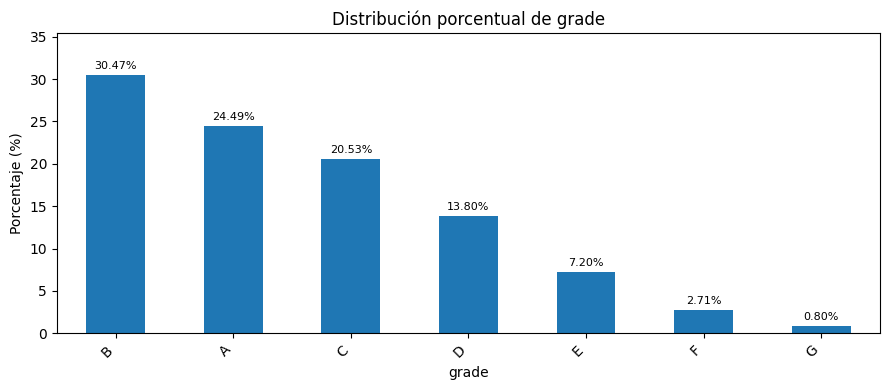

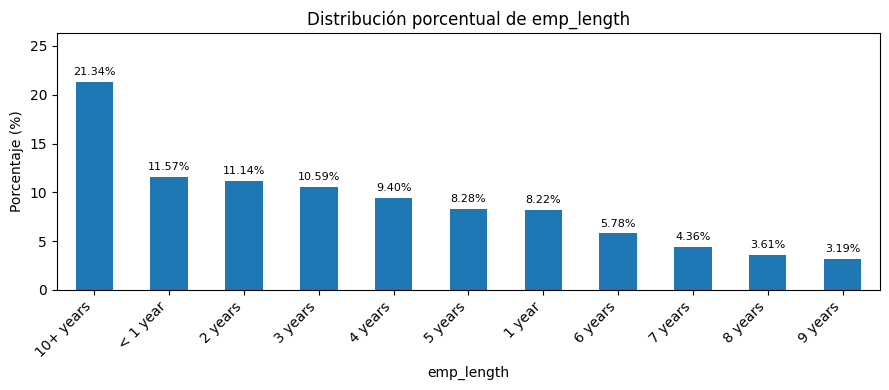

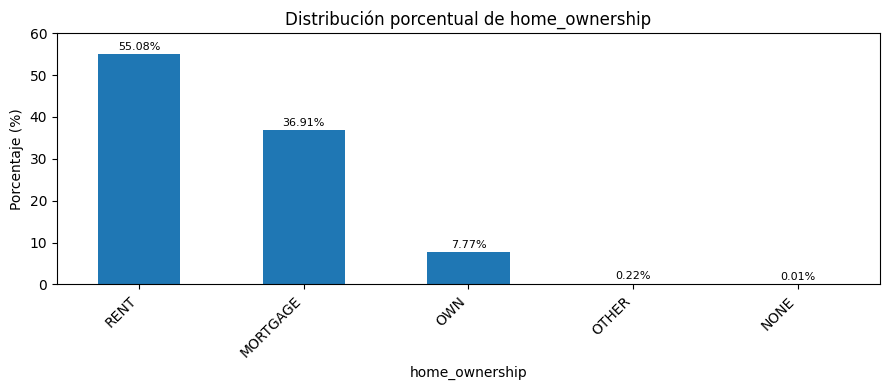

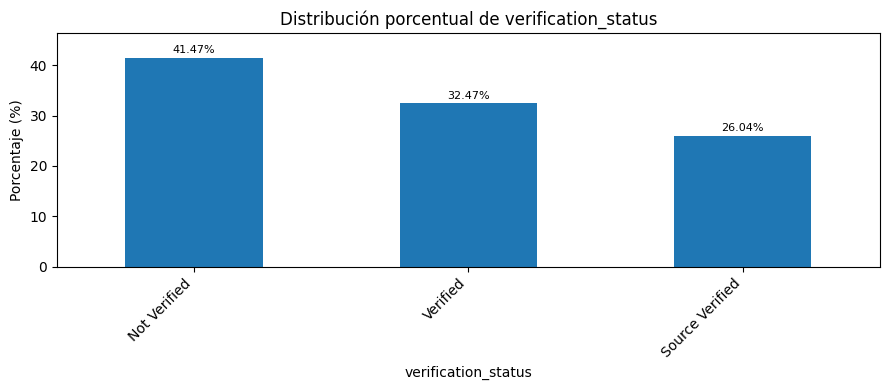

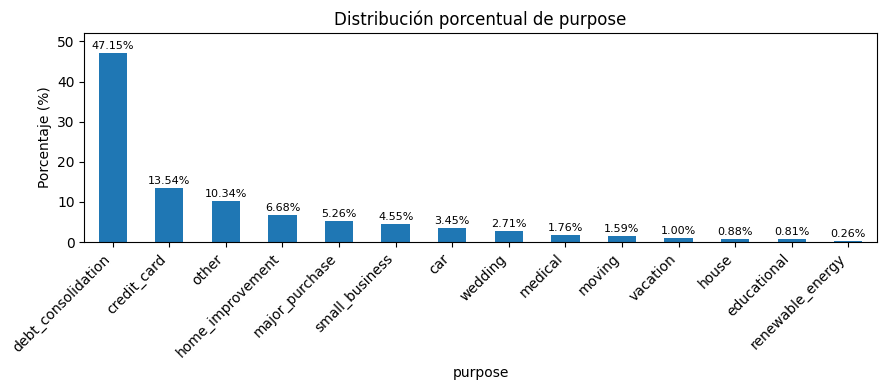

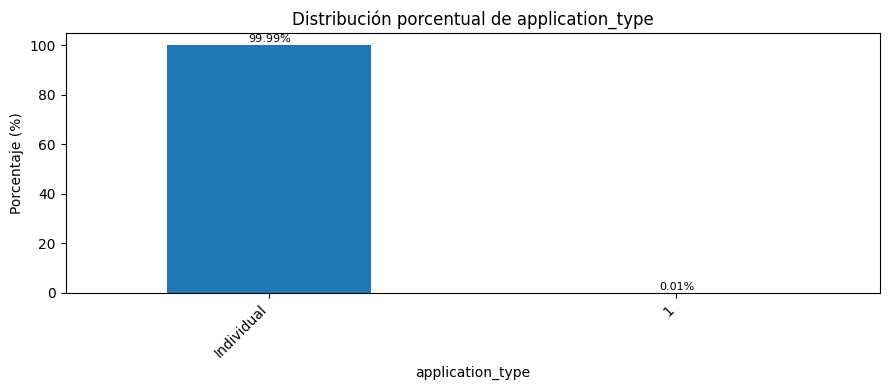

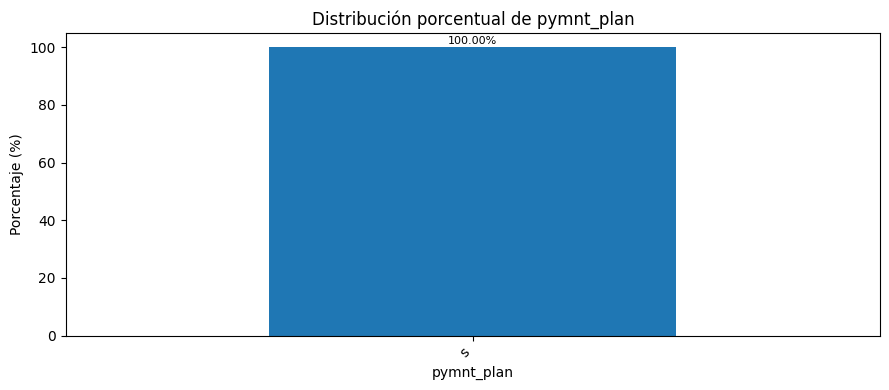

In [54]:
for variable in variables:
    counts = data[variable].value_counts()
    porcentajes = (counts / len(data)) * 100

    ax = porcentajes.plot(kind='bar', figsize=(9, 4))

    plt.title(f'Distribución porcentual de {variable}')
    plt.xlabel(variable)
    plt.ylabel('Porcentaje (%)')
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, porcentajes.max() + 5)  # Ajustar el límite superior del eje y

    # Mostrar porcentaje encima de cada barra
    for i, porcentaje in enumerate(porcentajes):
        ax.text(i, porcentaje + 0.5, f'{porcentaje:.2f}%',
                ha='center', va='bottom', fontsize=8, color='black')

    plt.tight_layout()
    plt.show()

````

En el listado observamos algunas variables que no aportan información, dado que presentan desbalance extremo o falta total de variabilidad por lo que no contribuyen a explicar la variabilidad de la variable objetivo.

(*) Categoría única (varianza cero): Toda la columna tiene el mismo valor → no aporta ninguna capacidad de discriminación para el modelo.

(*) Desbalance extremo (p. ej. 98% en una clase y 2% en otra): La información es muy pobre para aprender patrones, y en la práctica puede sesgar al modelo hacia la clase mayoritaria.

Tratamiento recomendado en la base de datos para este tipo de variables:

(*) Variables con una sola categoría: Eliminarlas directamente, ya que no añaden información útil.

(*) Variables con desbalance extremo: Eliminarlas si el desbalance es crítico y no aporta valor analítico.

````

Antes de construir cualquier modelo , es fundamental realizar un análisis exploratorio de datos (EDA). En este proceso, las gráficas cumplen un papel clave porque permiten visualizar la información y comprender tanto el comportamiento individual de las variables como sus interacciones.



1. Análisis univariante (una variable)

- Entender la distribución de las variables (balance, simetría, dispersión).
- Detectar sesgos o desbalances, por ejemplo cuando una categoría domina sobre las demás.
- Identificar valores atípicos o extremos, que podrían distorsionar el comportamiento del modelo.
- Comparar la importancia relativa de categorías, observando cuáles son más frecuentes o representativas.

2. Beneficios del análisis bivariante (dos variables)

- Explorar relaciones entre variables (numéricas vs numéricas, categóricas vs numéricas, categóricas vs categóricas).
- Detectar correlaciones o dependencias que pueden ser útiles para la predicción.
- Observar patrones de comportamiento diferenciados: por ejemplo, cómo varía la tasa de interés según el plazo del préstamo, o cómo el ingreso anual se distribuye en distintas categorías.

3. Relevancia para el modelado

Las gráficas exploratorias no solo ayudan a conocer los datos en profundidad, sino que también orientan las decisiones de preprocesamiento (eliminar variables sin varianza, transformar variables muy sesgadas, balancear categorías desproporcionadas, etc.).


Crearemos histogramas para las variables numéricas.



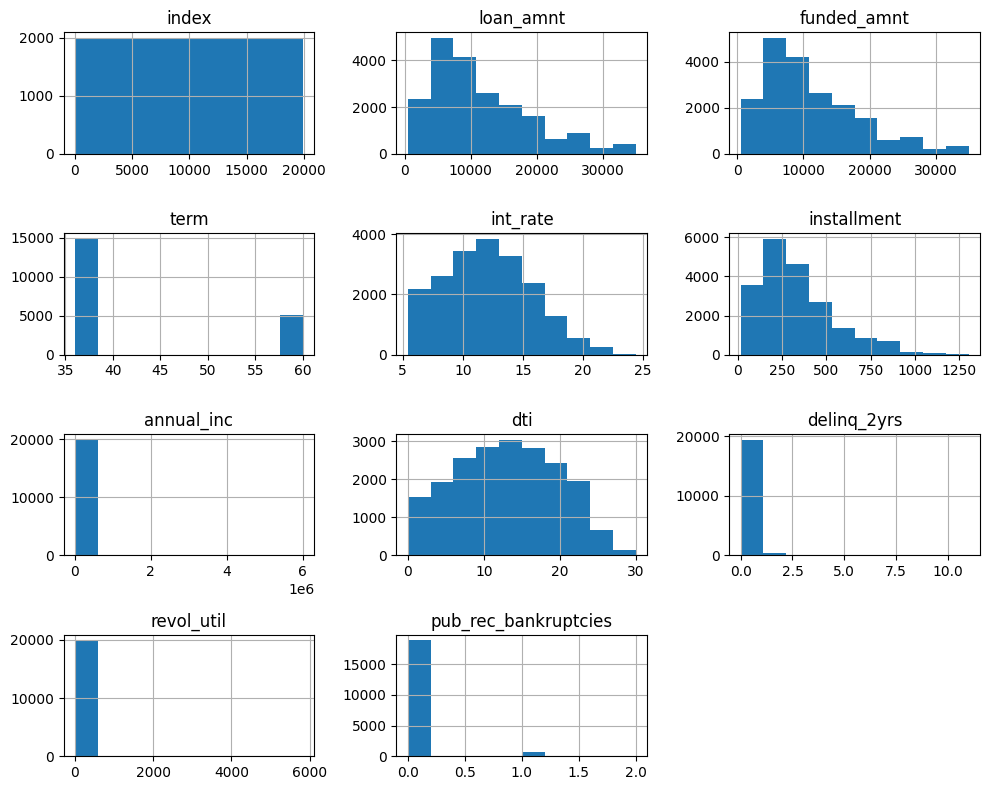

In [61]:
data[['index', 'loan_amnt', 'funded_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs',
      'revol_util', 'pub_rec_bankruptcies']].hist(figsize=(10, 8), bins=10)
plt.tight_layout()
plt.show()

Crearemos boxplot para las variables numéricas.

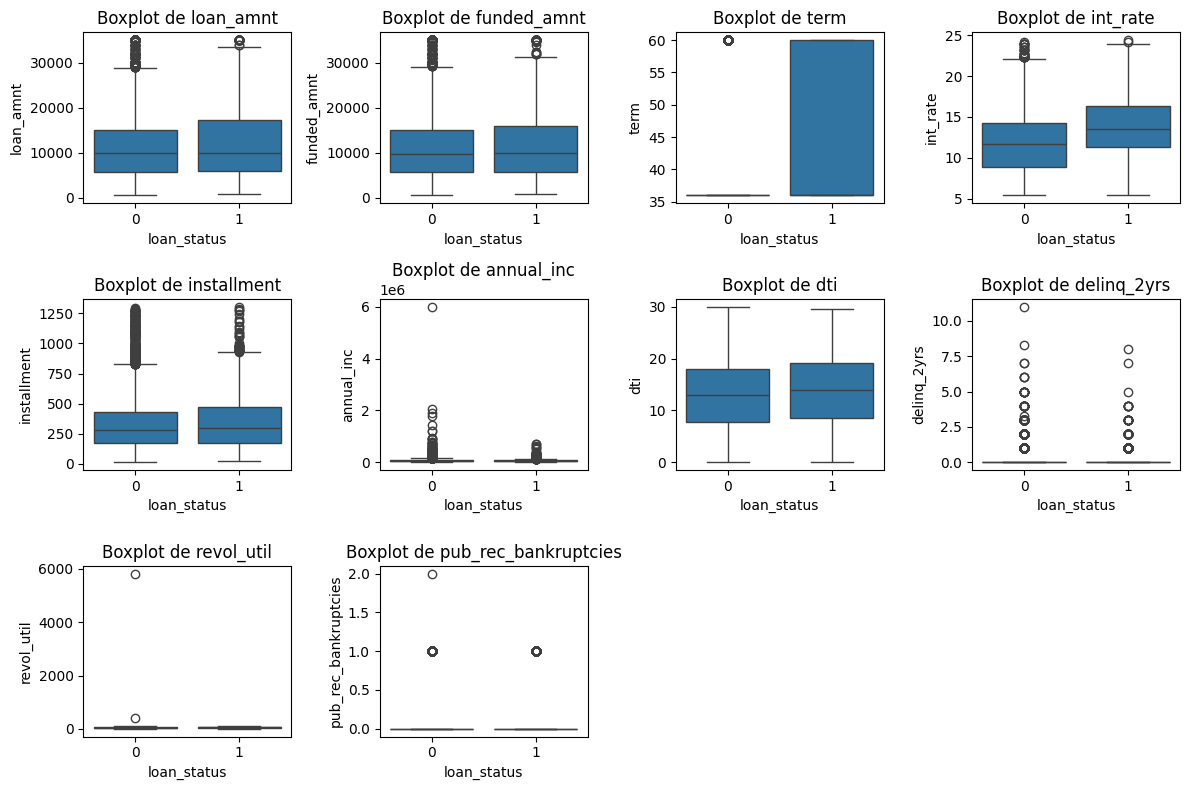

In [62]:
variables = ['loan_amnt', 'funded_amnt', 'term', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs',
      'revol_util', 'pub_rec_bankruptcies']

plt.figure(figsize=(12, 8))
for var in variables:
    plt.subplot(3, 4, variables.index(var) + 1)
    sns.boxplot(x='loan_status', y=var, data=data)
    plt.title(f'Boxplot de {var}')
    plt.xlabel('loan_status')
    plt.ylabel(var)
plt.tight_layout()
plt.show()

Crearemos algunas gráficas adicionales


**Loan Term, Interest Rate, Annual Income**

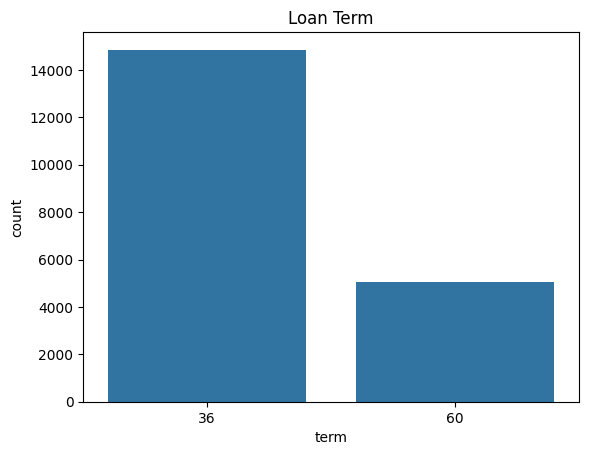

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(data=data, x='term', order=sorted(data['term'].unique()))
ax.set_title('Loan Term')

plt.show()

**Interest Rate**

<Axes: >

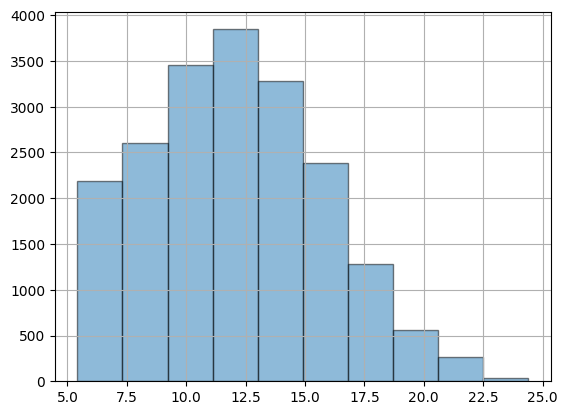

In [66]:
data.int_rate.hist(edgecolor='black', alpha=0.5)

**Tasa de Interés ('interest_rate') promedio de diferentes Plazos ('terms').**

In [67]:
data.groupby('term').agg({'int_rate':'mean'})

,int_rate
term,
36,11.121125
60,14.934955


**Loan Grade**

In [217]:
grade_counts = data['grade'].value_counts()
grade_counts

,count
grade,
B,6065
A,4875
C,4087
D,2748
E,1434
F,540
G,159


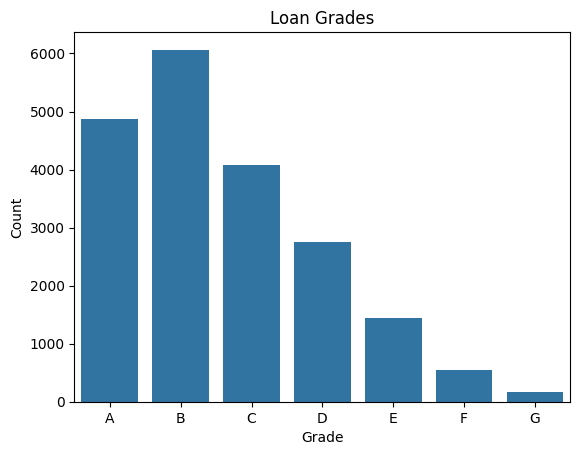

Number of different loan grades: 7


In [218]:
ax = sns.countplot(x='grade', data=data, order=sorted(data['grade'].unique()))

ax.set_title('Loan Grades')
ax.set_xlabel('Grade')
ax.set_ylabel('Count')

plt.show()

num_grades = len(grade_counts)
print("Number of different loan grades:", num_grades)

**Loan Grade and Interest Rate**

Obtenemos la tasa de interés promedio para cada 'grade'.

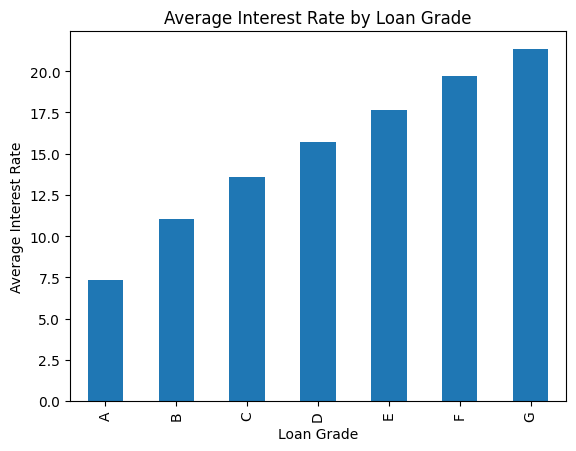

Average Interest Rate by Loan Grade:
grade
A     7.350978
B    11.033439
C    13.555241
D    15.707576
E    17.653752
F    19.729463
G    21.346981
Name: int_rate, dtype: float64


In [219]:
avg_int_rate = data.groupby('grade')['int_rate'].mean()

ax = avg_int_rate.plot(kind='bar')

ax.set_title('Average Interest Rate by Loan Grade')
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Average Interest Rate')

plt.show()

print("Average Interest Rate by Loan Grade:")
print(avg_int_rate)

Número de préstamos (Loan) por Estado (State)

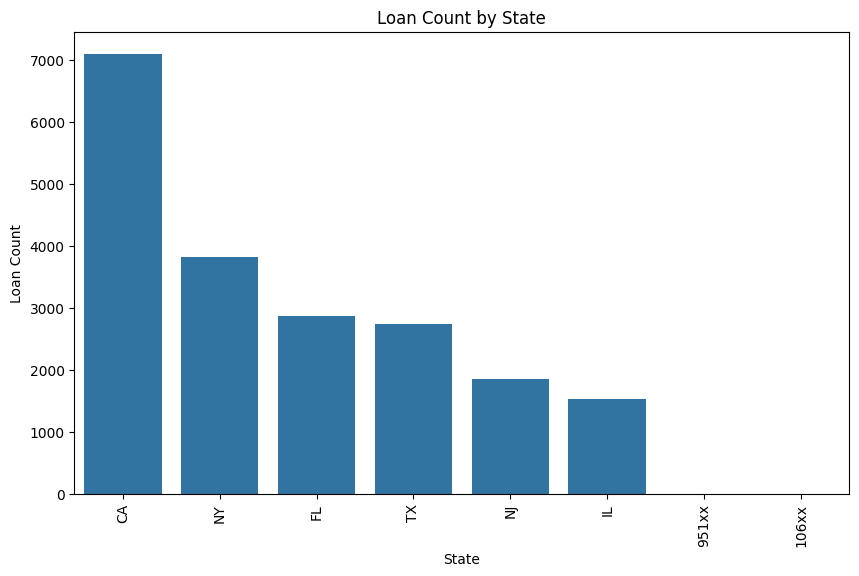

In [220]:
import seaborn as sns
import matplotlib.pyplot as plt

state_order = data['addr_state'].value_counts().index

plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='addr_state', order=state_order)
plt.xlabel('State')
plt.ylabel('Loan Count')
plt.title('Loan Count by State')
plt.xticks(rotation=90)
plt.show()

**Distribución del Ingreso Anual**


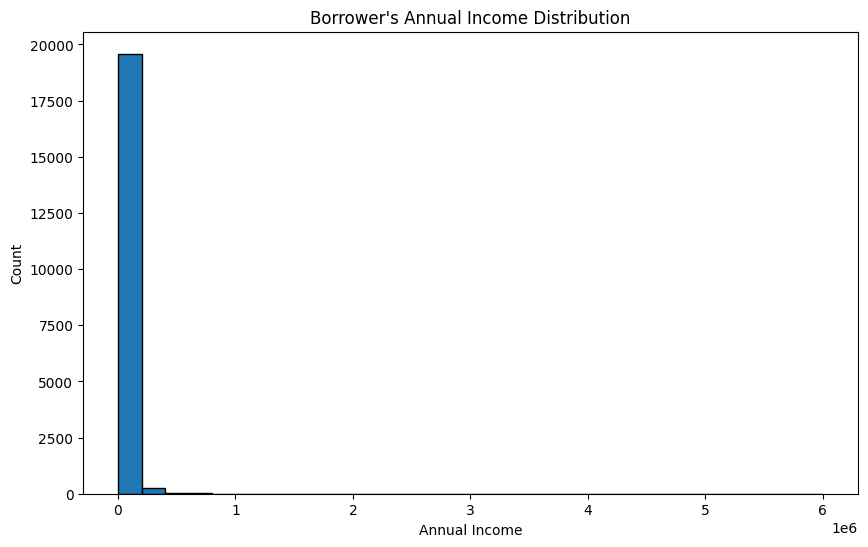

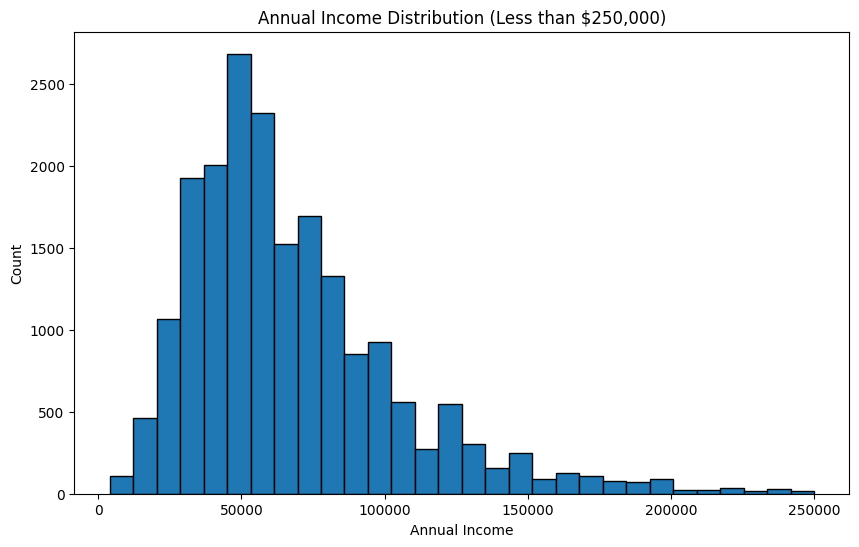

In [221]:
# borrower's annual income
plt.figure(figsize=(10, 6))
plt.hist(data['annual_inc'], bins=30, edgecolor='black')
plt.title("Borrower's Annual Income Distribution")
plt.xlabel('Annual Income')
plt.ylabel('Count')
plt.show()

# annual income less than $250,000
plt.figure(figsize=(10, 6))
plt.hist(data[data['annual_inc'] < 250000]['annual_inc'], bins=30, edgecolor='black')
plt.title("Annual Income Distribution (Less than $250,000)")
plt.xlabel('Annual Income')
plt.ylabel('Count')
plt.show()

**Ingreso Anual (annual_inc) Medio por Estado (State)**

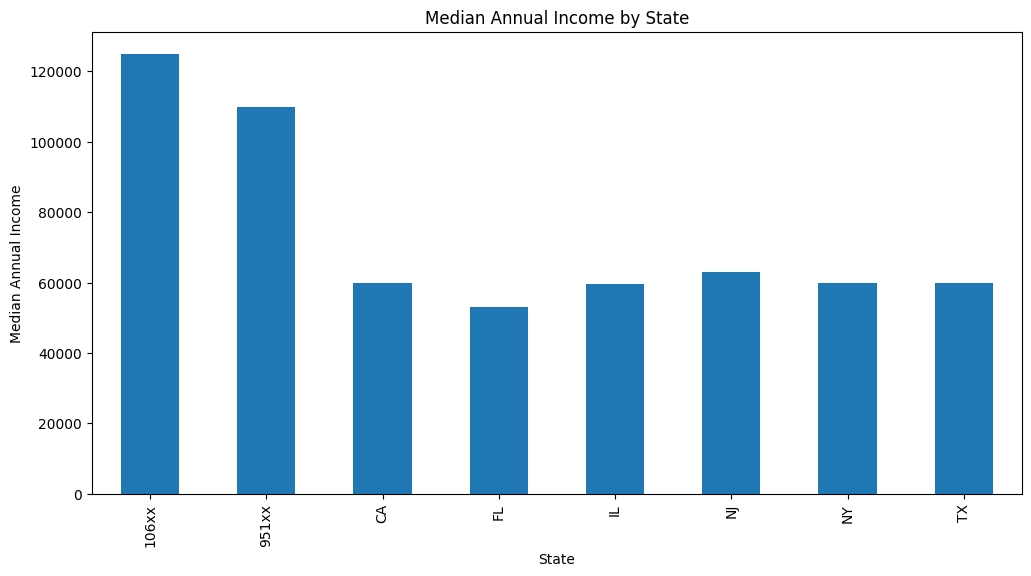

In [222]:
median_income_by_state = data.groupby('addr_state')['annual_inc'].median()
ax = median_income_by_state.plot.bar(figsize=(12, 6))
ax.set_xlabel('State')
ax.set_ylabel('Median Annual Income')
ax.set_title('Median Annual Income by State')
plt.show()

**Ingreso Anual (annual_inc) por Tasa de Interés (interest_rate)**

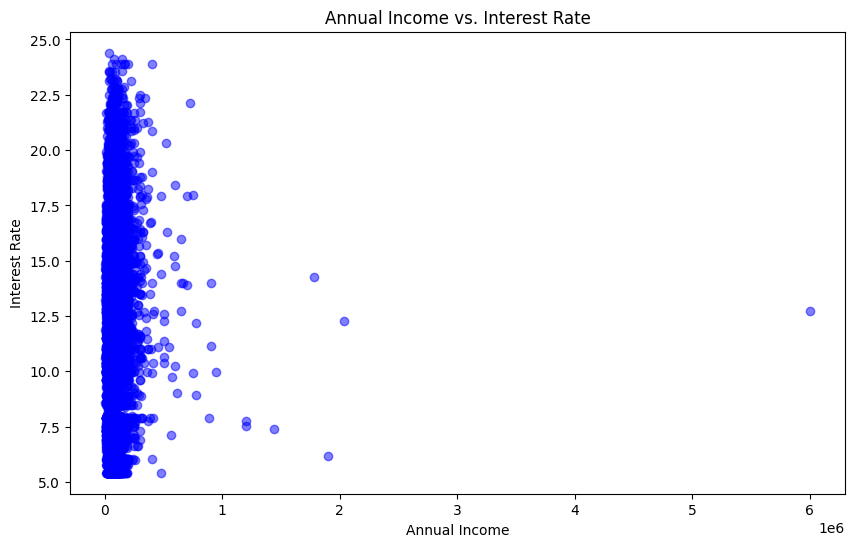

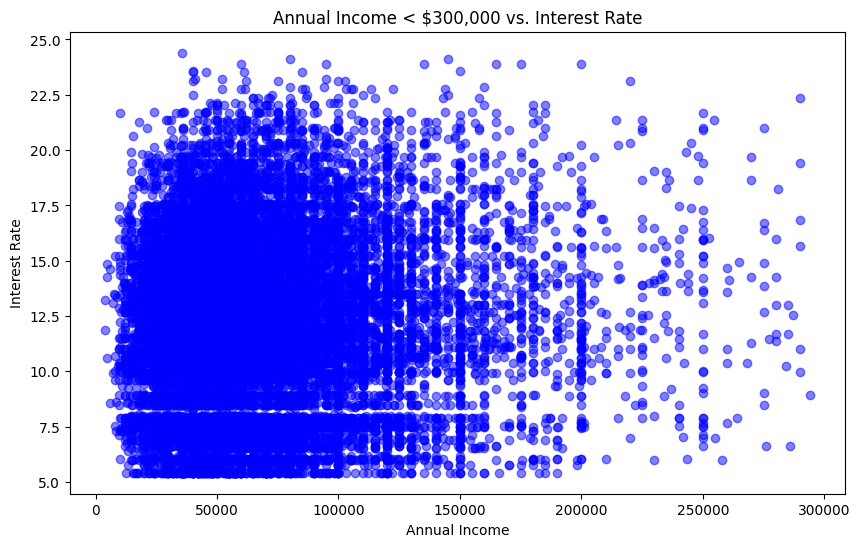

In [223]:
# Plot scatter plot of annual income and interest rate
plt.figure(figsize=(10, 6))
plt.scatter(data['annual_inc'], data['int_rate'], color='blue', alpha=0.5)
plt.title('Annual Income vs. Interest Rate')
plt.xlabel('Annual Income')
plt.ylabel('Interest Rate')
plt.show()

# Plot scatter plot of annual income less than $300,000 and interest rate
plt.figure(figsize=(10, 6))
plt.scatter(data[data['annual_inc'] < 300000]['annual_inc'], data[data['annual_inc'] < 300000]['int_rate'], color='blue', alpha=0.5)
plt.title('Annual Income < $300,000 vs. Interest Rate')
plt.xlabel('Annual Income')
plt.ylabel('Interest Rate')
plt.show()


**Préstamos por año**



/tmp/ipython-input-357699811.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data['issue_year'] = pd.to_datetime(data['issue_d']).dt.year


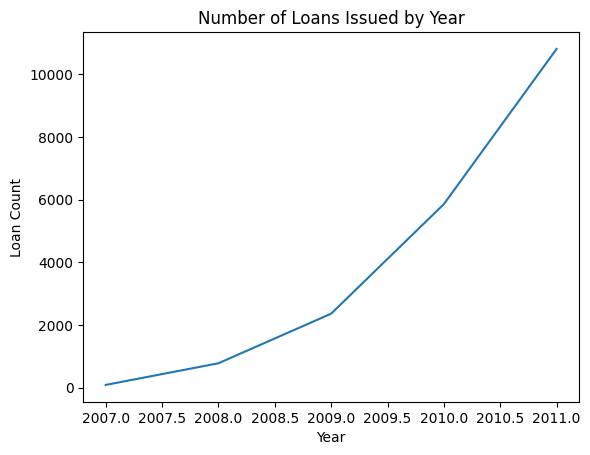

In [224]:
data['issue_year'] = pd.to_datetime(data['issue_d']).dt.year
loan_count_by_year = data.groupby('issue_year').size()
ax = loan_count_by_year.plot.line()
ax.set_title('Number of Loans Issued by Year')
ax.set_xlabel('Year')
ax.set_ylabel('Loan Count')
plt.show()

**Tasas de Interés por Año**



<Figure size 1000x600 with 0 Axes>

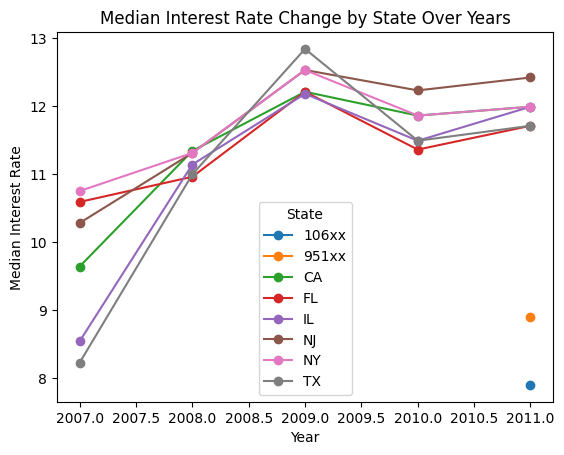

In [225]:
pivot_table = data.pivot_table(index='issue_year', columns='addr_state', values='int_rate', aggfunc='median')
plt.figure(figsize=(10, 6))
pivot_table.plot.line(marker='o')
plt.title('Median Interest Rate Change by State Over Years')
plt.xlabel('Year')
plt.ylabel('Median Interest Rate')
plt.legend(title='State')
plt.show()

# 7.Primer Data Cleaning → tratamiento de nulos


Los valores nulos representan información faltante en el dataset. Si no se tratan, reducen la calidad de los datos porque generan huecos en el análisis. Un dataset con demasiados nulos transmite poca confianza y puede inducir a interpretaciones equivocadas en los resultados.

1. Impacto en el modelado

Muchos algoritmos de machine learning no aceptan valores NaN (Not a Number), es decir, valores faltantes, desconocidos o no definidos (no significa que los valores sean cero, sino que no existen o no se registraron).

2. Pérdida de información

Eliminar filas o columnas con NaN sin analizar puede generar la pérdida de información valiosa. Por ejemplo, si una columna tiene un 10% de nulos, descartarla elimina el 90% de datos útiles. En vez de borrarlos, conviene imputar valores para aprovechar al máximo el dataset.

3. Sesgos en el análisis

Los nulos no siempre son aleatorios: a veces reflejan patrones ocultos. Por ejemplo, si los ingresos faltan principalmente en un grupo específico de clientes, imputarlos sin criterio puede introducir sesgos. Por eso, es importante analizar primero la naturaleza de los nulos para entender si la ausencia de datos es en sí misma una variable informativa.

4. Técnicas de imputación

El tratamiento de nulos debe considerar la elección de una estrategia adecuada según el contexto y el tipo de variable. Algunas opciones son:
- Simple: imputar con medidas estadísticas básicas como la media, mediana o moda.
- Regla: asignar valores basados en criterios específicos, por ejemplo, crear una categoría “Missing” en variables categóricas.
- Avanzada: aplicar métodos más sofisticados como KNN Imputer, regresiones para estimar valores faltantes o la creación de un flag que indique la ausencia de datos.

Imprimiremos el conteo y porcentaje de NaN de las variables.

In [226]:
# Obtenemos el número de NaN por variable
nan_por_variable = data.isnull().sum()

# Calculamos el porcentaje de NaN por variable
porcentaje_nan_por_variable = (nan_por_variable / len(data)) * 100

# Imprimimos el número de NaN y el porcentaje de NaN por variable
for variable in data.columns:
    print(f"Variable: {variable}")
    print(f"Número de NaN: {nan_por_variable[variable]}")
    print(f"Porcentaje de NaN: {porcentaje_nan_por_variable[variable]:.2f}%")
    print()

Variable: index
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: loan_amnt
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: funded_amnt
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: term
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: int_rate
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: installment
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: grade
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: emp_title
Número de NaN: 1185
Porcentaje de NaN: 5.95%

Variable: emp_length
Número de NaN: 502
Porcentaje de NaN: 2.52%

Variable: home_ownership
Número de NaN: 3
Porcentaje de NaN: 0.02%

Variable: annual_inc
Número de NaN: 3
Porcentaje de NaN: 0.02%

Variable: verification_status
Número de NaN: 3
Porcentaje de NaN: 0.02%

Variable: issue_d
Número de NaN: 3
Porcentaje de NaN: 0.02%

Variable: loan_status
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: pymnt_plan
Número de NaN: 0
Porcentaje de NaN: 0.00%

Variable: purpose
Número de NaN: 3
Porcent

Podemos identificar nulos ademas de por conteo y proporciones, listando directamente las variables con algún nulo.

In [227]:
variables_con_nan = data.columns[data.isna().any()].tolist()
print("Variables con valores NaN:")
print(variables_con_nan)

Variables con valores NaN:
['emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'revol_util', 'pub_rec_bankruptcies', 'issue_year']


In [228]:
data = data.fillna(data.median(numeric_only=True))
data.head()

,index,loan_amnt,funded_amnt,term,int_rate,installment,grade,emp_title,emp_length,home_ownership,...,loan_status,pymnt_plan,purpose,addr_state,dti,delinq_2yrs,revol_util,application_type,pub_rec_bankruptcies,issue_year
0,1,2400,2400,36,15.96,84.33,C,NaN,10+ years,RENT,...,0,s,small_business,IL,8.72,0.0,98.5,Individual,0.0,2011.0
1,2,10000,10000,36,13.49,339.31,C,AIR RESOURCES BOARD,10+ years,RENT,...,0,s,other,CA,20.00,0.0,21.0,Individual,0.0,2011.0
2,3,3000,3000,36,18.64,109.43,E,MKC Accounting,9 years,RENT,...,0,s,car,CA,5.35,0.0,87.5,Individual,0.0,2011.0
3,4,5600,5600,60,21.28,152.39,F,NaN,4 years,OWN,...,1,s,small_business,CA,5.55,0.0,32.6,Individual,0.0,2011.0
4,5,5375,5375,60,12.69,121.45,B,Starbucks,< 1 year,RENT,...,1,s,other,TX,18.08,0.0,36.5,Individual,0.0,2011.0



# 8.Feature Engineering → codificación de categóricas (dummies/one-hot).



Consiste en transformar, crear o agrupar variables para mejorar la capacidad predictiva del modelo. En este caso, transformar el target de texto a numérico es un paso obligatorio, mientras que en las variables predictoras (features) también se pueden aplicar técnicas como:

- Agrupar categorías raras para evitar clases con muy pocos registros.

- Transformar texto a número (ej. años de experiencia → número).

- Normalizar o escalar variables numéricas para homogenizar magnitudes.

- Crear nuevas variables derivadas de las originales (ej. ratio ingreso/deuda).

Sin estas transformaciones, no se puede dividir correctamente la data en entrenamiento y prueba.

Modificaremos la variable 'emp_length' para convertir las categorías a valores numéricos.

In [229]:
# Diccionario de mapeo
mapping = {
    '10+ years': 10,
    '9 years': 9,
    '8 years': 8,
    '7 years': 7,
    '6 years': 6,
    '5 years': 5,
    '4 years': 4,
    '3 years': 3,
    '2 years': 2,
    '1 year': 1,
    '< 1 year': 0
}

# Aplicamos el mapeo y asignamos 0 a vacíos/NaN
data['emp_length_numeric'] = data['emp_length'].map(mapping).fillna(0).astype(int)

print(data['emp_length_numeric'].value_counts().sort_index())

emp_length_numeric
0     2806
1     1636
2     2218
3     2108
4     1871
5     1649
6     1151
7      867
8      718
9      635
10    4249
Name: count, dtype: int64


Modificaremos el formato de la variable issue_d (de fecha, hora a año).

In [230]:
# Convertimos issue_d a año, sin NaN
s = pd.to_datetime(
        data['issue_d'].astype(str).str.strip(),
        format='%b-%Y',
        errors='coerce'        # convierte a NaT (Not a Time: equivalente a NaN pero para variables de tipo fecha/datetime.) lo que no encaje
    )

# Fallback: intentamos inferir formato en los que quedaron como NaT
mask = s.isna()
if mask.any():
    s.loc[mask] = pd.to_datetime(data.loc[mask, 'issue_d'], errors='coerce')

issue_year = s.dt.year
modo = issue_year.dropna().mode()[0]   # valor más frecuente
data['issue_year'] = issue_year.fillna(modo).astype('int64')

print("Años únicos en issue_year:", np.sort(data['issue_year'].unique()))


Años únicos en issue_year: [2007 2008 2009 2010 2011]



Los algoritmos de machine learning requieren trabajar con valores numéricos. Realizaremos un proceso de dummificación transformando variables categóricas en columnas numéricas binarias (0 o 1) que indican la presencia de cada categoría.


Ejemplo:

(*) Variable original:
- home_ownership = ['RENT', 'MORTGAGE', 'OWN']

(*) Variables tras get_dummies():
- home_ownership_RENT
- home_ownership_MORTGAGE
- home_ownership_OWN

Como recomendación, si intentamos aplicar pd.get_dummies() o cualquier codificación sobre columnas categóricas que contengan NaN, Python tratará el valor nulo como una categoría adicional (ej. "Missing"). Por ello, primero se recomienda imputar los nulos con alguna estrategia (moda, categoría "Missing", etc.), y luego se procede a la codificación.

Además de dummies (one-hot encoding), se pueden usar Label Encoding (para variables ordinales), Binary Encoding (reduce dimensionalidad), Target/Frequency Encoding (usa la relación con la variable objetivo o las frecuencias), Hashing Encoding (eficiente en alta cardinalidad) y Embeddings (vectores densos en deep learning).

In [231]:
# Generamos la lista de variables categóricas

categorical_columns = ['grade','home_ownership','verification_status',
                       'purpose','application_type','addr_state']

# Rellenamos NaN en categóricas
data[categorical_columns] = data[categorical_columns].fillna('Unknown')

# One-hot
data = pd.get_dummies(data, columns=categorical_columns, dummy_na=False)

data.head(5)

,index,loan_amnt,funded_amnt,term,int_rate,installment,emp_title,emp_length,annual_inc,issue_d,...,application_type_Individual,addr_state_106xx,addr_state_951xx,addr_state_CA,addr_state_FL,addr_state_IL,addr_state_NJ,addr_state_NY,addr_state_TX,addr_state_Unknown
0,1,2400,2400,36,15.96,84.33,NaN,10+ years,12252.0,Dec-2011,...,True,False,False,False,False,True,False,False,False,False
1,2,10000,10000,36,13.49,339.31,AIR RESOURCES BOARD,10+ years,49200.0,Dec-2011,...,True,False,False,True,False,False,False,False,False,False
2,3,3000,3000,36,18.64,109.43,MKC Accounting,9 years,48000.0,Dec-2011,...,True,False,False,True,False,False,False,False,False,False
3,4,5600,5600,60,21.28,152.39,NaN,4 years,40000.0,Dec-2011,...,True,False,False,True,False,False,False,False,False,False
4,5,5375,5375,60,12.69,121.45,Starbucks,< 1 year,15000.0,Dec-2011,...,True,False,False,False,False,False,False,False,True,False


#9.Segundo Data Cleaning → limpieza final y Revisión previa al modelado


En este ejercicio se ha considerado la eliminación de variables al final del proceso (antes del modelado) porque en ese momento ya se tiene certeza de qué columnas no aportan información predictiva y cuáles se han vuelto redundantes después de las transformaciones aplicadas, como Feature Engineering y One-Hot Encoding.

En concreto, se eliminan:

1. Variables de índice o identificadores: index
Razón: no aportan información predictiva, solo identifican filas.

2. Variables con texto libre: emp_title (título del puesto de trabajo).
Razón: Son muy diversas → demasiadas categorías únicas.

3. Variables categorizadas previamente o transformadas: emp_length → ya se convirtió a emp_length_numeric.
Razón: la versión original en texto ('10+ years', '5 years', etc.) ya no aporta nada adicional.

4. Variables de fecha: issue_d.
Razón: la fecha completa no suele usarse directamente.

5. Variables con valores únicos: pymnt_plan
Razón: no aporta poder discriminante si todos los valores son "n" o hay muy poca variabilidad o tienen el mismo valor.



In [232]:
variables=['index', 'emp_title', 'emp_length', 'issue_d', 'pymnt_plan']
data = data.drop(variables, axis=1)

Verificamos el tipo de variables en el dataset (cuántas son numéricas y cuántas categóricas) y revisamos si existen valores nulos en alguna columna.

De esta forma, nos aseguramos de que los datos estén listos y completos antes de entrenar un modelo de machine learning.

In [233]:
# Verificamos cuántas variables numéricas y categóricas hay
print("Numéricas:", data.select_dtypes(include='number').shape[1])
print("Categóricas:", data.select_dtypes(exclude='number').shape[1])

# Revisamos si hay nulos en alguna columna
print("\nColumnas con nulos:")
print(data.isnull().sum()[data.isnull().sum() > 0])

Numéricas: 13
Categóricas: 43

Columnas con nulos:
Series([], dtype: int64)


#10.Train y Test



Dividiremos la base de datos en train y test () considerando una partición 80/20.

In [234]:
# Dividimos los datos en características (X) y variable objetivo (y)
X = data.drop('loan_status', axis=1)
y = data['loan_status']

# Dividimos los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Imprimimos la forma de los conjuntos de entrenamiento y prueba
print('Forma de X_train:', X_train.shape)
print('Forma de y_train:', y_train.shape)
print('Forma de X_test:', X_test.shape)
print('Forma de y_test:', y_test.shape)

Forma de X_train: (15926, 55)
Forma de y_train: (15926,)
Forma de X_test: (3982, 55)
Forma de y_test: (3982,)


In [235]:
X_train.head()

,loan_amnt,funded_amnt,term,int_rate,installment,annual_inc,dti,delinq_2yrs,revol_util,pub_rec_bankruptcies,...,application_type_Individual,addr_state_106xx,addr_state_951xx,addr_state_CA,addr_state_FL,addr_state_IL,addr_state_NJ,addr_state_NY,addr_state_TX,addr_state_Unknown
8665,5200,5200,36,9.63,166.89,98000.0,19.80,0.0,70.3,0.0,...,True,False,False,True,False,False,False,False,False,False
16865,12500,12500,36,11.48,412.11,65000.0,1.63,0.0,36.4,0.0,...,True,False,False,True,False,False,False,False,False,False
4031,7000,7000,36,11.49,230.80,72000.0,18.30,0.0,61.5,0.0,...,True,False,False,True,False,False,False,False,False,False
11508,20000,12150,36,6.54,372.61,62000.0,18.02,0.0,39.1,0.0,...,True,False,False,False,False,False,False,True,False,False
14922,9600,9600,60,16.82,237.66,46095.0,12.86,0.0,86.5,1.0,...,True,False,False,False,False,True,False,False,False,False


In [236]:
y_train.head()

,loan_status
8665,0
16865,0
4031,0
11508,0
14922,1


#11.Entrenamiento de algoritmos

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


498/498 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


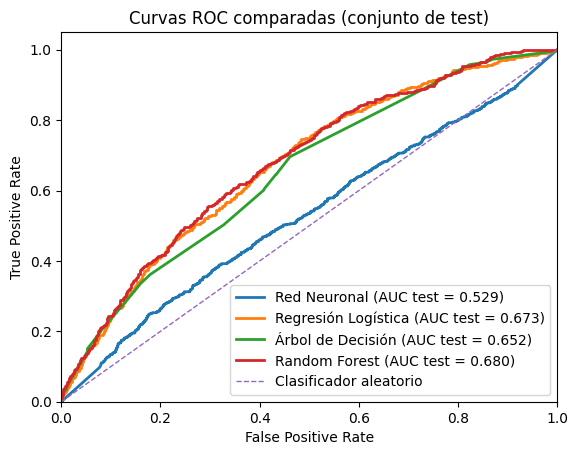

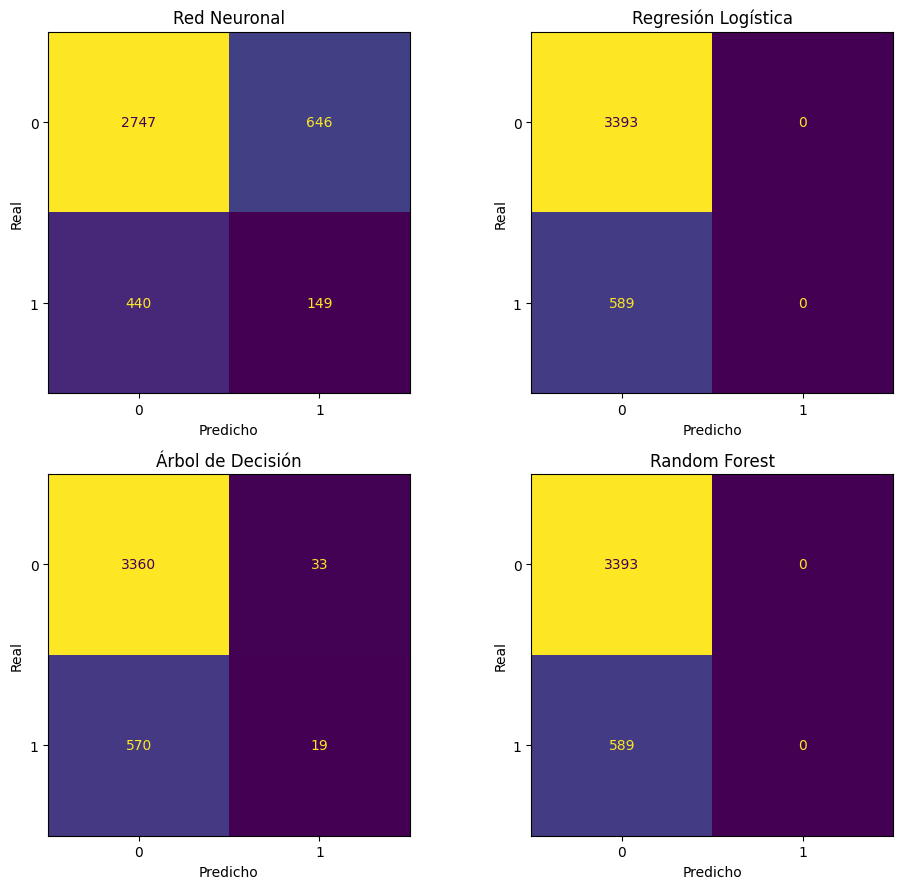

             Modelo  Acc Train  Acc Test  AUC Train  AUC Test
      Random Forest      0.852     0.852      0.703     0.680
Regresión Logística      0.852     0.852      0.678     0.673
  Árbol de Decisión      0.854     0.849      0.691     0.652
       Red Neuronal      0.717     0.727      0.511     0.529

Desglose matriz de confusión (test):
             Modelo   TN  FP  FN  TP
       Red Neuronal 2747 646 440 149
Regresión Logística 3393   0 589   0
  Árbol de Decisión 3360  33 570  19
      Random Forest 3393   0 589   0


In [245]:
# ============================================
# 0) Imports y semillas
# ============================================


import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_curve, roc_auc_score, ConfusionMatrixDisplay,
    confusion_matrix
)

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------
# Asume que ya tienes X (features) e y (target binario 0/1)
# --------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# ============================================
# 1) Definimos y entrenamos modelos
# ============================================
modelos = {}

# 1.1) Red Neuronal (llamada 'model')
model = Sequential([
    Dense(100, input_shape=(X_train.shape[1],), activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2, verbose=0)
modelos['Red Neuronal'] = model

# 1.2) Regresión Logística
logreg = LogisticRegression(max_iter=1000, n_jobs=None)
logreg.fit(X_train, y_train)
modelos['Regresión Logística'] = logreg

# 1.3) Árbol de Decisión
tree_clf = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_clf.fit(X_train, y_train)
modelos['Árbol de Decisión'] = tree_clf

# 1.4) Random Forest
rnd = RandomForestClassifier(
    n_estimators=150, max_features=5, max_leaf_nodes=12, random_state=42
)
rnd.fit(X_train, y_train)
modelos['Random Forest'] = rnd
import pandas as pd
from sklearn.metrics import accuracy_score

# ============================================
# 2) Probabilidades, predicciones y métricas
# ============================================
probas_train, probas_test = {}, {}
preds_train, preds_test = {}, {}
aucs_train, aucs_test = {}, {}
acc_train, acc_test = {}, {}

for nombre, m in modelos.items():
    # --- Probabilidades ---
    if nombre == 'Red Neuronal':
        p_train = m.predict(X_train).ravel()
        p_test  = m.predict(X_test).ravel()
    else:
        p_train = m.predict_proba(X_train)[:, 1]
        p_test  = m.predict_proba(X_test)[:, 1]

    probas_train[nombre] = p_train
    probas_test[nombre]  = p_test

    # --- Predicciones duras (umbral 0.5) ---
    yhat_train = (p_train >= 0.5).astype(int)
    yhat_test  = (p_test  >= 0.5).astype(int)
    preds_train[nombre] = yhat_train
    preds_test[nombre]  = yhat_test

    # --- Métricas ---
    aucs_train[nombre] = roc_auc_score(y_train, p_train)
    aucs_test[nombre]  = roc_auc_score(y_test,  p_test)
    acc_train[nombre]  = accuracy_score(y_train, yhat_train)
    acc_test[nombre]   = accuracy_score(y_test,  yhat_test)

# ============================================
# 3) Curva ROC única con AUC (test) en la leyenda
# ============================================
plt.figure()
for nombre, p in probas_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC test = {aucs_test[nombre]:.3f})")
plt.plot([0, 1], [0, 1], lw=1, linestyle='--', label="Clasificador aleatorio")
plt.xlim([0, 1]); plt.ylim([0, 1.05])
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Curvas ROC comparadas (conjunto de test)')
plt.legend(loc='lower right')
plt.show()

# ============================================
# 4) Matrices de confusión (test)
# ============================================
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
axes = axes.ravel()
for ax, (nombre, y_pred) in zip(axes, preds_test.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=[0, 1])
    disp.plot(ax=ax, values_format='d', colorbar=False)
    ax.set_title(nombre)
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
plt.tight_layout(); plt.show()

# ============================================
# 5) Tabla resumen (Accuracy y AUC en train/test)
# ============================================
rows = []
for nombre in modelos.keys():
    rows.append({
        "Modelo": nombre,
        "Acc Train": acc_train[nombre],
        "Acc Test":  acc_test[nombre],
        "AUC Train": aucs_train[nombre],
        "AUC Test":  aucs_test[nombre],
    })
df_metrics = pd.DataFrame(rows).sort_values("AUC Test", ascending=False)
print(df_metrics.round(3).to_string(index=False))

# (Opcional) desglose TN/FP/FN/TP en tabla
conf_rows = []
for nombre in modelos.keys():
    tn, fp, fn, tp = confusion_matrix(y_test, preds_test[nombre], labels=[0, 1]).ravel()
    conf_rows.append({"Modelo": nombre, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
df_conf = pd.DataFrame(conf_rows)
print("\nDesglose matriz de confusión (test):")
print(df_conf.to_string(index=False))


#10. Importancia de variables

Evaluaremos la importancia de las variables en ambos modelos decisión tree y random forest.

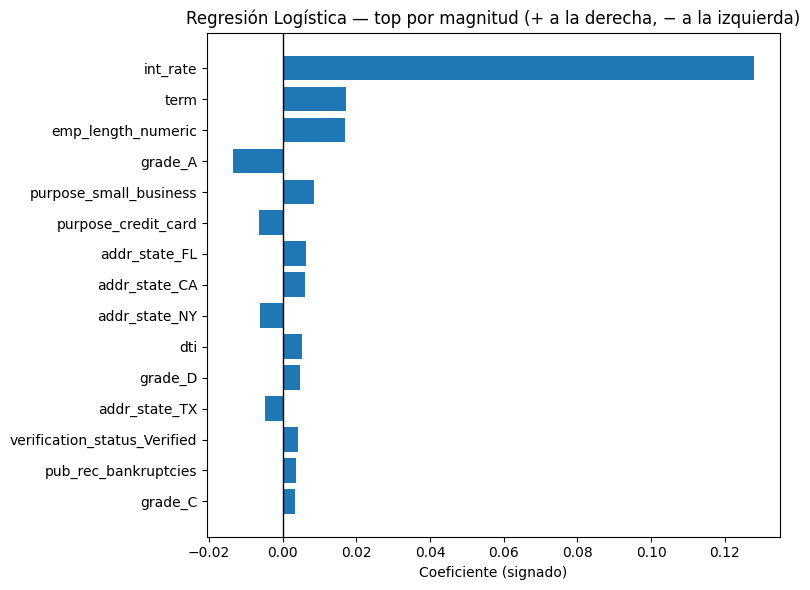


Top coeficientes (positivos y negativos) — Regresión Logística:
                            feature      coef signo
                           int_rate  0.127871     +
                               term  0.017337     +
                 emp_length_numeric  0.016961     +
             purpose_small_business  0.008496     +
                      addr_state_FL  0.006251     +
                      addr_state_CA  0.006167     +
                                dti  0.005149     +
                            grade_A -0.013379     −
                purpose_credit_card -0.006345     −
                      addr_state_NY -0.006049     −
                      addr_state_TX -0.004672     −
verification_status_Source Verified -0.003038     −
                        purpose_car -0.002150     −
                         issue_year -0.001930     −


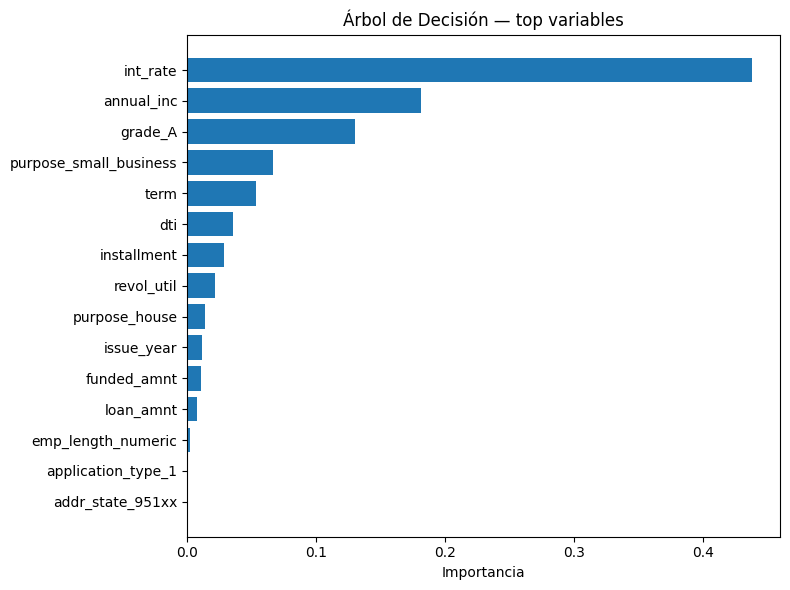


Top-15 Árbol de Decisión:
               feature  importance
              int_rate    0.437587
            annual_inc    0.181163
               grade_A    0.129822
purpose_small_business    0.066470
                  term    0.053566
                   dti    0.035158
           installment    0.028771
            revol_util    0.021236
         purpose_house    0.013976
            issue_year    0.011489
           funded_amnt    0.010841
             loan_amnt    0.007595
    emp_length_numeric    0.002325
    application_type_1    0.000000
      addr_state_951xx    0.000000


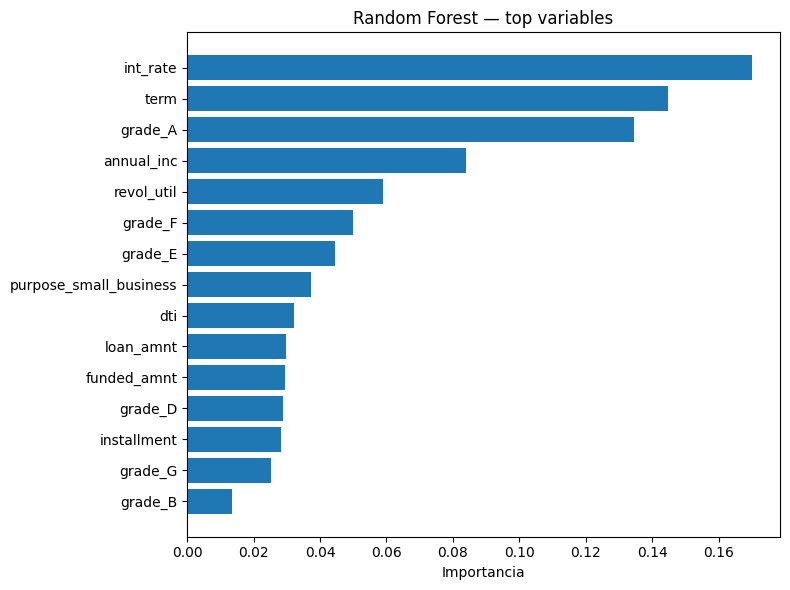


Top-15 Random Forest:
               feature  importance
              int_rate    0.170009
                  term    0.144717
               grade_A    0.134463
            annual_inc    0.083814
            revol_util    0.058980
               grade_F    0.049887
               grade_E    0.044522
purpose_small_business    0.037316
                   dti    0.032249
             loan_amnt    0.029638
           funded_amnt    0.029314
               grade_D    0.028914
           installment    0.028367
               grade_G    0.025266
               grade_B    0.013536


  0%|          | 0/1000 [00:00<?, ?it/s]

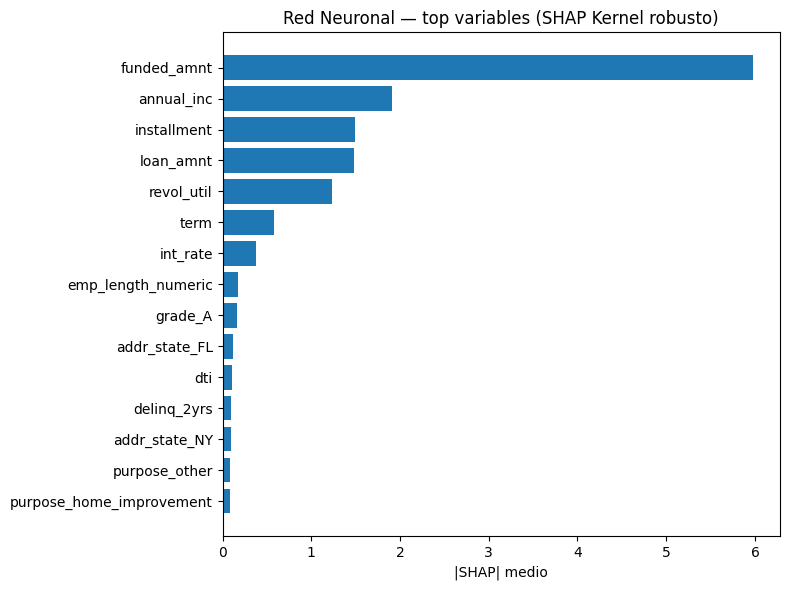


Top-15 Red Neuronal (|SHAP| medio):
                 feature  mean_abs_SHAP
             funded_amnt       5.983260
              annual_inc       1.909014
             installment       1.492655
               loan_amnt       1.482928
              revol_util       1.235091
                    term       0.575762
                int_rate       0.374234
      emp_length_numeric       0.175102
                 grade_A       0.167257
           addr_state_FL       0.115005
                     dti       0.108272
             delinq_2yrs       0.094232
           addr_state_NY       0.091835
           purpose_other       0.087010
purpose_home_improvement       0.086775


In [253]:
top_k = 15
feature_names = np.array(getattr(X, "columns", np.arange(X.shape[1])))

# ---------- Regresión Logística ----------
coef_log = logreg.coef_[0]
idx_mag = np.argsort(np.abs(coef_log))[-top_k:]
vals, labs = coef_log[idx_mag], feature_names[idx_mag]

plt.figure(figsize=(8,6))
plt.barh(range(len(idx_mag)), vals)
plt.yticks(range(len(idx_mag)), labs)
plt.axvline(0, color='k', lw=1)
plt.xlabel('Coeficiente (signado)')
plt.title('Regresión Logística — top por magnitud (+ a la derecha, − a la izquierda)')
plt.tight_layout(); plt.show()

# Tabla con top positivos y top negativos (más interpretables)
k_half = top_k // 2
top_pos = np.argsort(coef_log)[-k_half:][::-1]
top_neg = np.argsort(coef_log)[:k_half]
tbl_log = pd.DataFrame({
    "feature": np.r_[feature_names[top_pos], feature_names[top_neg]],
    "coef":    np.r_[coef_log[top_pos],      coef_log[top_neg]],
    "signo":   np.r_[np.repeat("+", len(top_pos)), np.repeat("−", len(top_neg))]
})
print("\nTop coeficientes (positivos y negativos) — Regresión Logística:")
print(tbl_log.to_string(index=False))

# ---------- Árbol de Decisión----------
imp_tree = tree_clf.feature_importances_
idx_tree = np.argsort(imp_tree)[-top_k:][::-1]

plt.figure(figsize=(8,6))
plt.barh(range(len(idx_tree)), imp_tree[idx_tree])
plt.yticks(range(len(idx_tree)), feature_names[idx_tree])
plt.gca().invert_yaxis()
plt.xlabel('Importancia')
plt.title('Árbol de Decisión — top variables')
plt.tight_layout(); plt.show()

print("\nTop-15 Árbol de Decisión:")
print(pd.DataFrame({"feature": feature_names[idx_tree], "importance": imp_tree[idx_tree]}).to_string(index=False))

# ---------- 6.3 Random Forest ----------
imp_rf = rnd.feature_importances_
idx_rf = np.argsort(imp_rf)[-top_k:][::-1]

plt.figure(figsize=(8,6))
plt.barh(range(len(idx_rf)), imp_rf[idx_rf])
plt.yticks(range(len(idx_rf)), feature_names[idx_rf])
plt.gca().invert_yaxis()
plt.xlabel('Importancia')
plt.title('Random Forest — top variables')
plt.tight_layout(); plt.show()

print("\nTop-15 Random Forest:")
print(pd.DataFrame({"feature": feature_names[idx_rf], "importance": imp_rf[idx_rf]}).to_string(index=False))

# ---------- SHAP para Red Neuronal: KernelExplainer ----------
import shap

top_k = 15
feature_names = np.array(getattr(X, "columns", np.arange(X.shape[1])))

# 1) Utilidad para limpiar NaN/Inf y castear a float32
def clean_array(A):
    A = np.asarray(A, dtype=np.float32)
    # sustituir NaN e infinitos por 0 (o el valor que prefieras)
    A = np.nan_to_num(A, nan=0.0, posinf=0.0, neginf=0.0)
    return A

# 2) Background reducido (kmeans) o sample si prefieres
try:
    bg_np = shap.kmeans(clean_array(X_train), 50)  # más rápido y estable que 200 filas crudas
except Exception:
    bg_np = clean_array(X_train.sample(min(100, len(X_train)), random_state=42).values)

# 3) Muestra de test a explicar (limpia y numpy)
xt_np = clean_array(X_test.sample(min(1000, len(X_test)), random_state=42).values)

# 4) Predictor con clipping para evitar logit(0) y logit(1)
def f_prob(Z):
    p = model.predict(clean_array(Z), verbose=0).ravel()
    return np.clip(p, 1e-6, 1-1e-6)  # evita ±∞ en logit

# 5) Explainer y SHAP values
try:
    explainer = shap.KernelExplainer(f_prob, bg_np, link="logit")
    shap_vals = explainer.shap_values(xt_np, nsamples=200)
except Exception:
    # fallback si el logit sigue dando guerra: usar identidad (sin logit)
    explainer = shap.KernelExplainer(lambda Z: model.predict(clean_array(Z), verbose=0).ravel(),
                                     bg_np, link="identity")
    shap_vals = explainer.shap_values(xt_np, nsamples=200)

# 6) Si viene lista (binario), tomar el primero
if isinstance(shap_vals, list):
    shap_vals = shap_vals[0]

# 7) Top-k por |SHAP| medio y gráfico
abs_mean = np.abs(shap_vals).mean(axis=0)
idx = np.argsort(abs_mean)[-top_k:][::-1]

plt.figure(figsize=(8, 6))
plt.barh(range(len(idx)), abs_mean[idx])
plt.yticks(range(len(idx)), feature_names[idx])
plt.gca().invert_yaxis()
plt.xlabel('|SHAP| medio')
plt.title('Red Neuronal — top variables (SHAP Kernel robusto)')
plt.tight_layout(); plt.show()

print("\nTop-15 Red Neuronal (|SHAP| medio):")
print(pd.DataFrame({"feature": feature_names[idx], "mean_abs_SHAP": abs_mean[idx]}).to_string(index=False))



  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipython-input-910193174.py:46: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


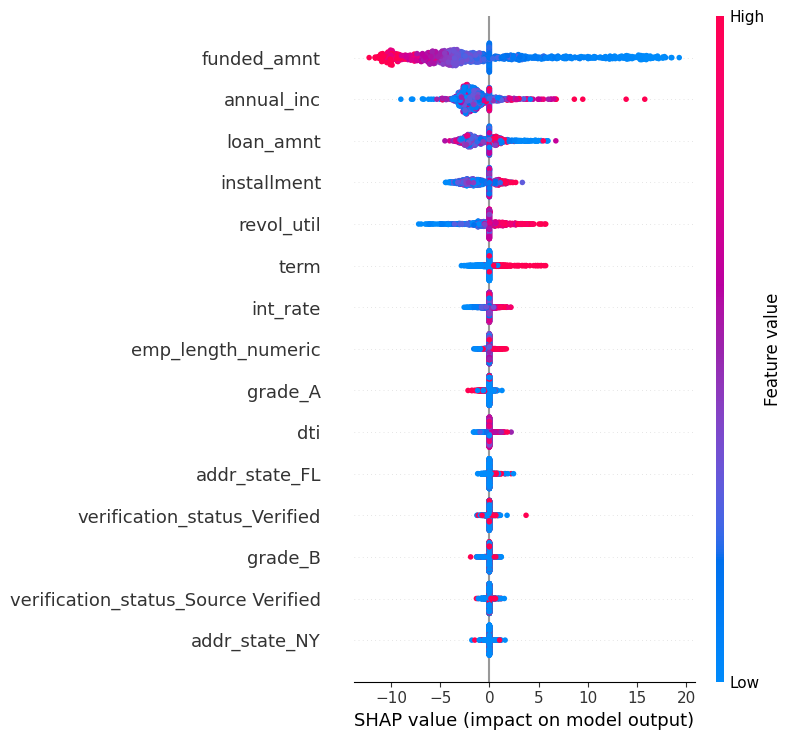

In [254]:
# ---------- SHAP para Red Neuronal: KernelExplainer ----------

import shap
import numpy as np

top_k = 15
feature_names = np.array(getattr(X, "columns", np.arange(X.shape[1])))

# Utilidades: limpiar NaN/Inf y castear a float32 (evita errores internos)
def _clean(A):
    A = np.asarray(A, dtype=np.float32)
    return np.nan_to_num(A, nan=0.0, posinf=0.0, neginf=0.0)

# Background resumido (más rápido/estable)
try:
    bg_np = shap.kmeans(_clean(X_train), 50)   # 50 centroides
except Exception:
    bg_np = _clean(X_train.sample(min(100, len(X_train)), random_state=42).values)

# Muestra a explicar
xt_np = _clean(X_test.sample(min(1000, len(X_test)), random_state=42).values)

# Predictor con clipping para evitar logit(0) o logit(1)
def _predict_prob(Z):
    p = model.predict(_clean(Z), verbose=0).ravel()
    return np.clip(p, 1e-6, 1-1e-6)

# Explainer + SHAP values
try:
    explainer = shap.KernelExplainer(_predict_prob, bg_np, link="logit")
    shap_vals = explainer.shap_values(xt_np, nsamples=200)
except Exception:
    # Fallback si hubiera algún problema con logit
    explainer = shap.KernelExplainer(lambda Z: model.predict(_clean(Z), verbose=0).ravel(),
                                     bg_np, link="identity")
    shap_vals = explainer.shap_values(xt_np, nsamples=200)

# Para binario, puede venir como lista
if isinstance(shap_vals, list):
    shap_vals = shap_vals[0]

# ---- Gráfico principal: SHAP summary (beeswarm) ----
# Cada punto = una observación; color: valor de la feature (rojo=alto, azul=bajo);
# Posición horizontal = impacto SHAP (izquierda disminuye prob., derecha aumenta).
shap.summary_plot(
    shap_vals,
    xt_np,
    feature_names=feature_names,
    max_display=top_k,   # cuántas variables mostrar
    plot_type="dot"      # beeswarm coloreado
)

#  **Tarea**

**Indicaciones:**

- Trabajar y ejecutar todo el código en Colab, verifique que el código completo funciona antes de remitirlo.
- Responder las preguntas en un documento en word, incluyendo los resultados obtenidos.
- Se entregarán tanto el código como el documento, el documento indicará los nombres de los integrantes.
- El trabajo será subido por solo uno de los integrantes.

**Preguntas:**


In [ ]:
1.	Arquitectura y entrenamiento
Entrenar un nuevo modelo de red neuronal aplicando las distintas estrategias vistas en clase para mejorar sus métricas (variación de arquitectura, funciones de activación, optimizadores, tasa de aprendizaje, número de épocas, regularización, dropout, early stopping, etc.) y comparar su desempeño frente a la red original y al mejor modelo base.
•	¿Cómo afecta el número de capas ocultas al rendimiento de la red neuronal mejorada frente a la red original y al Random Forest / Regresión Logística?
•	¿Qué impacto tiene variar el número de neuronas por capa en las métricas de la red?
•	¿Qué función de activación (ReLU, tanh, sigmoid) ofrece mejores resultados en la red?
•	¿Qué optimizador (SGD, Adam, RMSprop) logra una convergencia más rápida y estable en la red neuronal?
•	¿Cómo influye la tasa de aprendizaje en la convergencia de la red y qué tan sensible es frente al modelo de referencia?
•	¿Qué ocurre al variar el número de épocas?
•	¿Qué impacto tienen estrategias como Dropout, Momentum, Early Stopping, Regularización L1/L2, en la estabilidad y generalización de la red? (3 de 4 estrategias)
________________________________________
2. Desempeño y generalización (Matriz de Confusión + ROC)
•	¿Cómo cambian las métricas de clasificación de la red mejorada respecto a la red original y mejor modelo base?
•	¿La red mejorada generaliza mejor comparada con la red original y el mejor modelo base?
________________________________________
3. Interpretación de variables
•	Cuál es la diferencia en la interpretación de variables entre la regresión logística (a través de sus coeficientes), los árboles de decisión / Random Forest (mediante la importancia de variables o feature importance) y las redes neuronales (empleando técnicas de explicabilidad como SHAP)?
•	¿Qué variables tienen mayor contribución en la red neuronal según valores SHAP?
•	¿Cambió el ranking de importancia de variables después de modificar la arquitectura de la red?
•	¿Cómo se comparan esas importancias con los coeficientes de la regresión logística y con la feature importance del Random Forest? ¿Los tres modelos coinciden en las variables críticas o presentan discrepancias?
